# Atividade: rede neural com TensorFlow (Aulas 12 e 13)

Objetivo: implementar uma rede neural densa (MLP) com TensorFlow para classificar
dígitos manuscritos do conjunto `load_digits` do scikit-learn (imagens 8x8, 10 classes).

- **Aula 12:** construir a rede com a API `keras` e treiná-la com `model.fit`.
- **Aula 13:** entender o *backpropagation* e reimplementar o passo de treino com `tf.GradientTape`.

In [1]:
# Habilita a GPU: pré-carrega as bibliotecas CUDA do pacote nvidia antes de importar o TensorFlow.
import ctypes, glob, importlib.util, os
_pkg = os.path.dirname(importlib.util.find_spec("nvidia").submodule_search_locations[0])
for _lib in sorted(glob.glob(os.path.join(_pkg, "nvidia", "*", "lib", "*.so*"))):
    try:
        ctypes.CDLL(_lib, mode=ctypes.RTLD_GLOBAL)
    except OSError:
        pass
import tensorflow as tf
print("GPUs disponíveis:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1792895462.881384  284820 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Dados

Separamos treino, validação e teste de forma estratificada e normalizamos os pixels para [0, 1].

In [3]:
digits = load_digits()
X = digits.data.astype("float32") / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)
print(f"treino={len(X_train)}  validação={len(X_val)}  teste={len(X_test)}")

treino=1149  validação=288  teste=360


## 2. Arquitetura (Aula 12)

Duas camadas ocultas com ativação ReLU e uma camada de saída com softmax, uma probabilidade
por classe.

In [4]:
model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(64,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ],
    name="mlp_digitos",
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

I0000 00:00:1792895471.924451  284820 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4132 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "mlp_digitos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Treino com `model.fit`

O histórico guarda a perda e a acurácia de cada época, em treino e validação.

I0000 00:00:1792895473.111256  285145 service.cc:153] XLA service 0x7d0388033480 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792895473.111273  285145 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792895473.130542  285145 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792895473.231246  285145 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792895473.235921  285145 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1228__.13


I0000 00:00:1792895473.584385  285145 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


I0000 00:00:1792895474.110984  285244 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 12 bytes spill stores, 12 bytes spill loads



I0000 00:00:1792895475.217292  285145 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1792895475.337595  285146 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1228__.13


I0000 00:00:1792895475.514656  285146 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


I0000 00:00:1792895476.038662  285364 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 12 bytes spill stores, 12 bytes spill loads



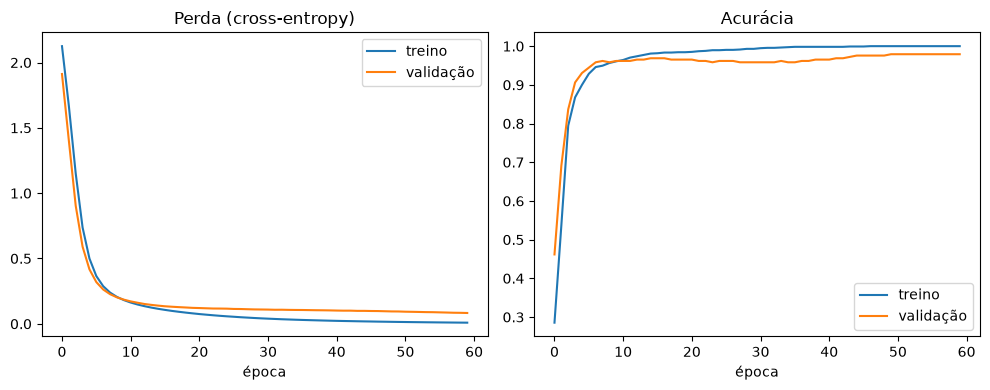

In [5]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=32,
    verbose=0,
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history["loss"], label="treino")
axes[0].plot(history.history["val_loss"], label="validação")
axes[0].set_title("Perda (cross-entropy)")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="treino")
axes[1].plot(history.history["val_accuracy"], label="validação")
axes[1].set_title("Acurácia")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

In [6]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Teste: perda={test_loss:.4f}  acurácia={test_accuracy:.4f}")

Teste: perda=0.0890  acurácia=0.9722


## 4. Backpropagation (Aula 13)

Para um neurônio com saída `ŷ = w·x` e perda quadrática `L = (ŷ - y)²`, a regra da cadeia dá:

`dL/dw = 2 · (ŷ - y) · x`

O `tf.GradientTape` registra as operações no forward pass e calcula esse gradiente
automaticamente no backward pass. Conferimos as duas formas abaixo.

In [7]:
w = tf.Variable(0.5)
x, y_true = tf.constant(2.0), tf.constant(3.0)

with tf.GradientTape() as tape:
    y_hat = w * x
    loss = (y_hat - y_true) ** 2

grad_tape = tape.gradient(loss, w).numpy()
grad_manual = (2 * (0.5 * 2.0 - 3.0) * 2.0)
print(f"gradiente pelo GradientTape: {grad_tape:.4f}")
print(f"gradiente pela regra da cadeia: {grad_manual:.4f}")
assert np.isclose(grad_tape, grad_manual)

gradiente pelo GradientTape: -8.0000
gradiente pela regra da cadeia: -8.0000


## 5. Passo de treino escrito à mão

Reimplementamos o `model.fit` com um laço explícito: forward pass, cálculo da perda,
gradiente com `GradientTape` e atualização dos pesos pelo otimizador.

In [8]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
manual_model = tf.keras.models.clone_model(model)
manual_model.set_weights(model.get_weights())  # começa do mesmo ponto que o modelo acima

@tf.function
def train_step(xb, yb):
    with tf.GradientTape() as tape:
        preds = manual_model(xb, training=True)
        loss = loss_fn(yb, preds)
    grads = tape.gradient(loss, manual_model.trainable_variables)
    optimizer.apply_gradients(zip(grads, manual_model.trainable_variables))
    return loss

dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(1000).batch(32)
for epoch in range(5):
    epoch_loss = np.mean([train_step(xb, yb).numpy() for xb, yb in dataset])
    print(f"época {epoch + 1}: perda média={epoch_loss:.4f}")

manual_acc = np.mean(manual_model(X_test, training=False).numpy().argmax(axis=1) == y_test)
print(f"acurácia no teste após 5 épocas à mão: {manual_acc:.4f}")

época 1: perda média=0.0107
época 2: perda média=0.0099
época 3: perda média=0.0080
época 4: perda média=0.0065
época 5: perda média=0.0062
acurácia no teste após 5 épocas à mão: 0.9722
